In [1]:
import os
print(os.listdir("data"))

['kaggle_survey_2021_responses.csv']


In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import os

sns.set_style("whitegrid")
os.makedirs("images", exist_ok=True)

raw = pd.read_csv("data/kaggle_survey_2021_responses.csv", low_memory=False)
questions = raw.iloc[0]          # row with the question text
df = raw.iloc[1:].reset_index(drop=True)   # real respondents only
print(df.shape)

(25973, 369)


In [2]:
for q in ["Q1", "Q2", "Q3", "Q4", "Q5", "Q6"]:
    print(q, "->", questions[q])

Q1 -> What is your age (# years)?
Q2 -> What is your gender? - Selected Choice
Q3 -> In which country do you currently reside?
Q4 -> What is the highest level of formal education that you have attained or plan to attain within the next 2 years?
Q5 -> Select the title most similar to your current role (or most recent title if retired): - Selected Choice
Q6 -> For how many years have you been writing code and/or programming?


In [3]:
df[["Q1", "Q2", "Q3", "Q4", "Q5", "Q6"]].head()

,Q1,Q2,Q3,Q4,Q5,Q6
0,50-54,Man,India,Bachelor’s degree,Other,5-10 years
1,50-54,Man,Indonesia,Master’s degree,Program/Project Manager,20+ years
2,22-24,Man,Pakistan,Master’s degree,Software Engineer,1-3 years
3,45-49,Man,Mexico,Doctoral degree,Research Scientist,20+ years
4,45-49,Man,India,Doctoral degree,Other,< 1 years


In [4]:
df[["Q1", "Q2", "Q3", "Q4", "Q5", "Q6"]].isnull().sum()

Q1    0
Q2    0
Q3    0
Q4    0
Q5    0
Q6    0
dtype: int64

In [5]:
print(df["Q1"].value_counts())
print(df["Q4"].value_counts())

Q1
25-29    4931
18-21    4901
22-24    4694
30-34    3441
35-39    2504
40-44    1890
45-49    1375
50-54     964
55-59     592
60-69     553
70+       128
Name: count, dtype: int64
Q4
Master’s degree                                                      10132
Bachelor’s degree                                                     9907
Doctoral degree                                                       2795
Some college/university study without earning a bachelor’s degree     1735
I prefer not to answer                                                 627
No formal education past high school                                   417
Professional doctorate                                                 360
Name: count, dtype: int64


In [6]:
df_clean = df.copy()
print("Duplicate rows:", df_clean.duplicated().sum())
df_clean = df_clean.drop_duplicates()
print("Rows now:", len(df_clean))

Duplicate rows: 0
Rows now: 25973


In [7]:
multi_cols = [c for c in df_clean.columns if "_Part_" in c or "_OTHER" in c]
single_cols = [c for c in df_clean.columns if c not in multi_cols]
print("Single-choice columns:", len(single_cols))
print("Multi-select columns:", len(multi_cols))

missing_pct = (df_clean[single_cols].isnull().mean() * 100).round(1)
print(missing_pct.sort_values(ascending=False).head(10))

Single-choice columns: 21
Multi-select columns: 348
Q35    91.4
Q28    88.0
Q33    82.1
Q26    41.5
Q25    40.7
Q23    38.6
Q22    37.9
Q21    37.4
Q20    37.1
Q41    28.8
dtype: float64


In [8]:
for col in df_clean.columns:
    if pd.api.types.is_string_dtype(df_clean[col]):
        df_clean[col] = df_clean[col].str.strip().str.replace("’", "'", regex=False)

df_clean = df_clean.replace({
    "I prefer not to answer": np.nan,
    "Prefer not to say": np.nan,
})

df_clean["Q3"] = df_clean["Q3"].replace({
    "United States of America": "USA",
    "United Kingdom of Great Britain and Northern Ireland": "UK",
})

In [9]:
print(df_clean["Q4"].value_counts(dropna=False))
print(df_clean["Q3"].value_counts().head(8))

Q4
Master's degree                                                      10132
Bachelor's degree                                                     9907
Doctoral degree                                                       2795
Some college/university study without earning a bachelor's degree     1735
NaN                                                                    627
No formal education past high school                                   417
Professional doctorate                                                 360
Name: count, dtype: int64
Q3
India      7434
USA        2650
Other      1270
Japan       921
China       814
Brazil      751
Russia      742
Nigeria     702
Name: count, dtype: int64


In [10]:
for q in ["Q20", "Q25", "Q26", "Q28", "Q33", "Q35"]:
    print(q, "->", questions[q])

Q20 -> In what industry is your current employer/contract (or your most recent employer if retired)? - Selected Choice
Q25 -> What is your current yearly compensation (approximate $USD)?
Q26 -> Approximately how much money have you (or your team) spent on machine learning and/or cloud computing services at home (or at work) in the past 5 years (approximate $USD)?
Q28 -> Of the cloud platforms that you are familiar with, which has the best developer experience (most enjoyable to use)? - Selected Choice
Q33 -> Which of the following big data products (relational database, data warehouse, data lake, or similar) do you use most often? - Selected Choice
Q35 -> Which of the following business intelligence tools do you use most often? - Selected Choice


In [11]:
age_order = sorted(df_clean["Q1"].dropna().unique())   # '18-21' ... '70+' sort correctly as text

edu_map = {
    "No formal education past high school": 1,
    "Some college/university study without earning a bachelor's degree": 2,
    "Bachelor's degree": 3,
    "Master's degree": 4,
    "Doctoral degree": 5,
    "Professional doctorate": 5,
}
code_map = {
    "I have never written code": 0,
    "< 1 years": 1,
    "1-3 years": 2,
    "3-5 years": 3,
    "5-10 years": 4,
    "10-20 years": 5,
    "20+ years": 6,
}

df_clean["Age_Rank"] = df_clean["Q1"].map({a: i + 1 for i, a in enumerate(age_order)})
df_clean["Education_Level"] = df_clean["Q4"].map(edu_map)
df_clean["Coding_Experience"] = df_clean["Q6"].map(code_map)

In [12]:
print("Unmapped Q4:", df_clean.loc[df_clean["Education_Level"].isnull() & df_clean["Q4"].notnull(), "Q4"].unique())
print("Unmapped Q6:", df_clean.loc[df_clean["Coding_Experience"].isnull() & df_clean["Q6"].notnull(), "Q6"].unique())
print(df_clean["Q6"].value_counts(dropna=False))

Unmapped Q4: <StringArray>
[]
Length: 0, dtype: str
Unmapped Q6: <StringArray>
[]
Length: 0, dtype: str
Q6
1-3 years                    7874
< 1 years                    5881
3-5 years                    4061
5-10 years                   3099
10-20 years                  2166
20+ years                    1860
I have never written code    1032
Name: count, dtype: int64


In [13]:
lookups = {}
for col in ["Q2", "Q3", "Q5"]:
    cat = df_clean[col].astype("category")
    df_clean[col + "_code"] = cat.cat.codes          # missing values become -1
    lookups[col] = dict(enumerate(cat.cat.categories))

print(lookups["Q2"])
df_clean[["Q2", "Q2_code", "Q3", "Q3_code"]].head()

{0: 'Man', 1: 'Nonbinary', 2: 'Prefer to self-describe', 3: 'Woman'}


,Q2,Q2_code,Q3,Q3_code
0,Man,0,India,23
1,Man,0,Indonesia,24
2,Man,0,Pakistan,41
3,Man,0,Mexico,34
4,Man,0,India,23


In [15]:
q7_cols = [c for c in df_clean.columns if c.startswith("Q7_")]

empty = [c for c in q7_cols if df_clean[c].notnull().sum() == 0]
print("Empty columns skipped:", empty)

lang = pd.DataFrame({
    df_clean[c].dropna().iloc[0]: df_clean[c].notnull().astype(int)
    for c in q7_cols if df_clean[c].notnull().sum() > 0
})

answered_q7 = lang.sum(axis=1) > 0
print("Answered Q7:", answered_q7.sum(), "of", len(lang))
lang.sum().sort_values(ascending=False)

Empty columns skipped: ['Q7_Part_12']
Answered Q7: 24622 of 25973


Python        21860
SQL           10756
C++            5535
R              5334
Java           4769
C              4709
Javascript     4332
MATLAB         2935
Other          2575
Bash           2216
Julia           305
Swift           242
dtype: int64

In [16]:
print(df_clean[["Education_Level", "Coding_Experience", "Age_Rank"]].describe().loc[["count", "min", "max"]])
print(df_clean.shape)

       Education_Level  Coding_Experience  Age_Rank
count          25346.0            25973.0   25973.0
min                1.0                0.0       1.0
max                5.0                6.0      11.0
(25973, 375)


In [17]:
flags = lang.add_prefix("uses_")
an = pd.concat([df_clean, flags], axis=1)
an_q7 = an[answered_q7]
print(an_q7.shape)

(24622, 387)


In [18]:
lang_share = (lang[answered_q7].mean() * 100).sort_values(ascending=False).round(1)
print(lang_share)

Python        88.8
SQL           43.7
C++           22.5
R             21.7
Java          19.4
C             19.1
Javascript    17.6
MATLAB        11.9
Other         10.5
Bash           9.0
Julia          1.2
Swift          1.0
dtype: float64


In [19]:
order_exp = ["I have never written code", "< 1 years", "1-3 years", "3-5 years",
             "5-10 years", "10-20 years", "20+ years"]
py_by_exp = (an_q7.groupby("Q6")["uses_Python"].mean() * 100).reindex(order_exp).round(1)
sql_by_exp = (an_q7.groupby("Q6")["uses_SQL"].mean() * 100).reindex(order_exp).round(1)
print(pd.DataFrame({"Python_%": py_by_exp, "SQL_%": sql_by_exp}))

                           Python_%  SQL_%
Q6                                        
I have never written code       NaN    NaN
< 1 years                      88.7   34.2
1-3 years                      91.5   40.8
3-5 years                      91.1   46.2
5-10 years                     86.6   51.1
10-20 years                    83.4   54.9
20+ years                      82.3   54.4


In [20]:
print("Top 5 countries (%):")
print((df_clean["Q3"].value_counts(normalize=True).head(5) * 100).round(1))
print("\nGender (%):")
print((df_clean["Q2"].value_counts(normalize=True) * 100).round(1))

Top 5 countries (%):
Q3
India    28.6
USA      10.2
Other     4.9
Japan     3.5
China     3.1
Name: proportion, dtype: float64

Gender (%):
Q2
Man                        80.4
Woman                      19.1
Nonbinary                   0.3
Prefer to self-describe     0.2
Name: proportion, dtype: float64


In [21]:
edu = df_clean["Education_Level"].dropna()
print("Master's or higher:", round((edu >= 4).mean() * 100, 1), "%")
print("Bachelor's or higher:", round((edu >= 3).mean() * 100, 1), "%")

Master's or higher: 52.4 %
Bachelor's or higher: 91.5 %


In [22]:
print((df_clean["Q5"].value_counts(normalize=True).head(6) * 100).round(1))

Q5
Student                   26.2
Data Scientist            13.9
Software Engineer          9.4
Other                      9.2
Data Analyst               8.9
Currently not employed     7.6
Name: proportion, dtype: float64


In [23]:
print(df_clean["Q25"].value_counts(dropna=False))

Q25
NaN                 10582
$0-999               3369
1,000-1,999           969
10,000-14,999         950
30,000-39,999         741
100,000-124,999       725
5,000-7,499           699
50,000-59,999         697
40,000-49,999         688
20,000-24,999         587
2,000-2,999           575
15,000-19,999         573
7,500-9,999           552
60,000-69,999         551
25,000-29,999         470
70,000-79,999         464
4,000-4,999           456
150,000-199,999       392
80,000-89,999         391
3,000-3,999           380
125,000-149,999       379
90,000-99,999         350
200,000-249,999       177
300,000-499,999        91
250,000-299,999        75
>$1,000,000            58
$500,000-999,999       32
Name: count, dtype: int64


In [24]:
comp_order = ["$0-999", "1,000-1,999", "2,000-2,999", "3,000-3,999", "4,000-4,999",
              "5,000-7,499", "7,500-9,999", "10,000-14,999", "15,000-19,999",
              "20,000-24,999", "25,000-29,999", "30,000-39,999", "40,000-49,999",
              "50,000-59,999", "60,000-69,999", "70,000-79,999", "80,000-89,999",
              "90,000-99,999", "100,000-124,999", "125,000-149,999", "150,000-199,999",
              "200,000-249,999", "250,000-299,999", "300,000-499,999",
              "$500,000-999,999", ">$1,000,000"]

comp_rank = {label: i + 1 for i, label in enumerate(comp_order)}
df_clean["Comp_Rank"] = df_clean["Q25"].map(comp_rank)

print("Unmapped:", df_clean.loc[df_clean["Comp_Rank"].isnull() & df_clean["Q25"].notnull(), "Q25"].unique())
print("Answered pay question:", df_clean["Comp_Rank"].notnull().sum())

Unmapped: <StringArray>
[]
Length: 0, dtype: str
Answered pay question: 15391


In [25]:
two = df_clean[df_clean["Q3"].isin(["USA", "India"]) & df_clean["Comp_Rank"].notnull()]
by_country = two.groupby("Q3")["Comp_Rank"].agg(["median", "count"])
by_country["Median_Pay_Band"] = by_country["median"].apply(lambda r: comp_order[int(r) - 1])
print(by_country)

       median  count  Median_Pay_Band
Q3                                   
India     6.0   3376      5,000-7,499
USA      19.0   1845  100,000-124,999


In [26]:
usa = df_clean[(df_clean["Q3"] == "USA") & df_clean["Comp_Rank"].notnull()]
med = usa.groupby("Q5")["Comp_Rank"].agg(["median", "count"])
med = med[med["count"] >= 50].sort_values("median", ascending=False)
med["Median_Pay_Band"] = med["median"].apply(lambda r: comp_order[int(r) - 1])
print(med)

                           median  count  Median_Pay_Band
Q5                                                       
Product Manager              21.0     52  150,000-199,999
Data Scientist               20.0    419  125,000-149,999
Machine Learning Engineer    20.0    102  125,000-149,999
Data Engineer                19.0     81  100,000-124,999
Program/Project Manager      19.0     96  100,000-124,999
Software Engineer            19.0    204  100,000-124,999
Research Scientist           18.0    156    90,000-99,999
Business Analyst             16.0     97    70,000-79,999
Data Analyst                 16.0    227    70,000-79,999
Other                        16.0    346    70,000-79,999


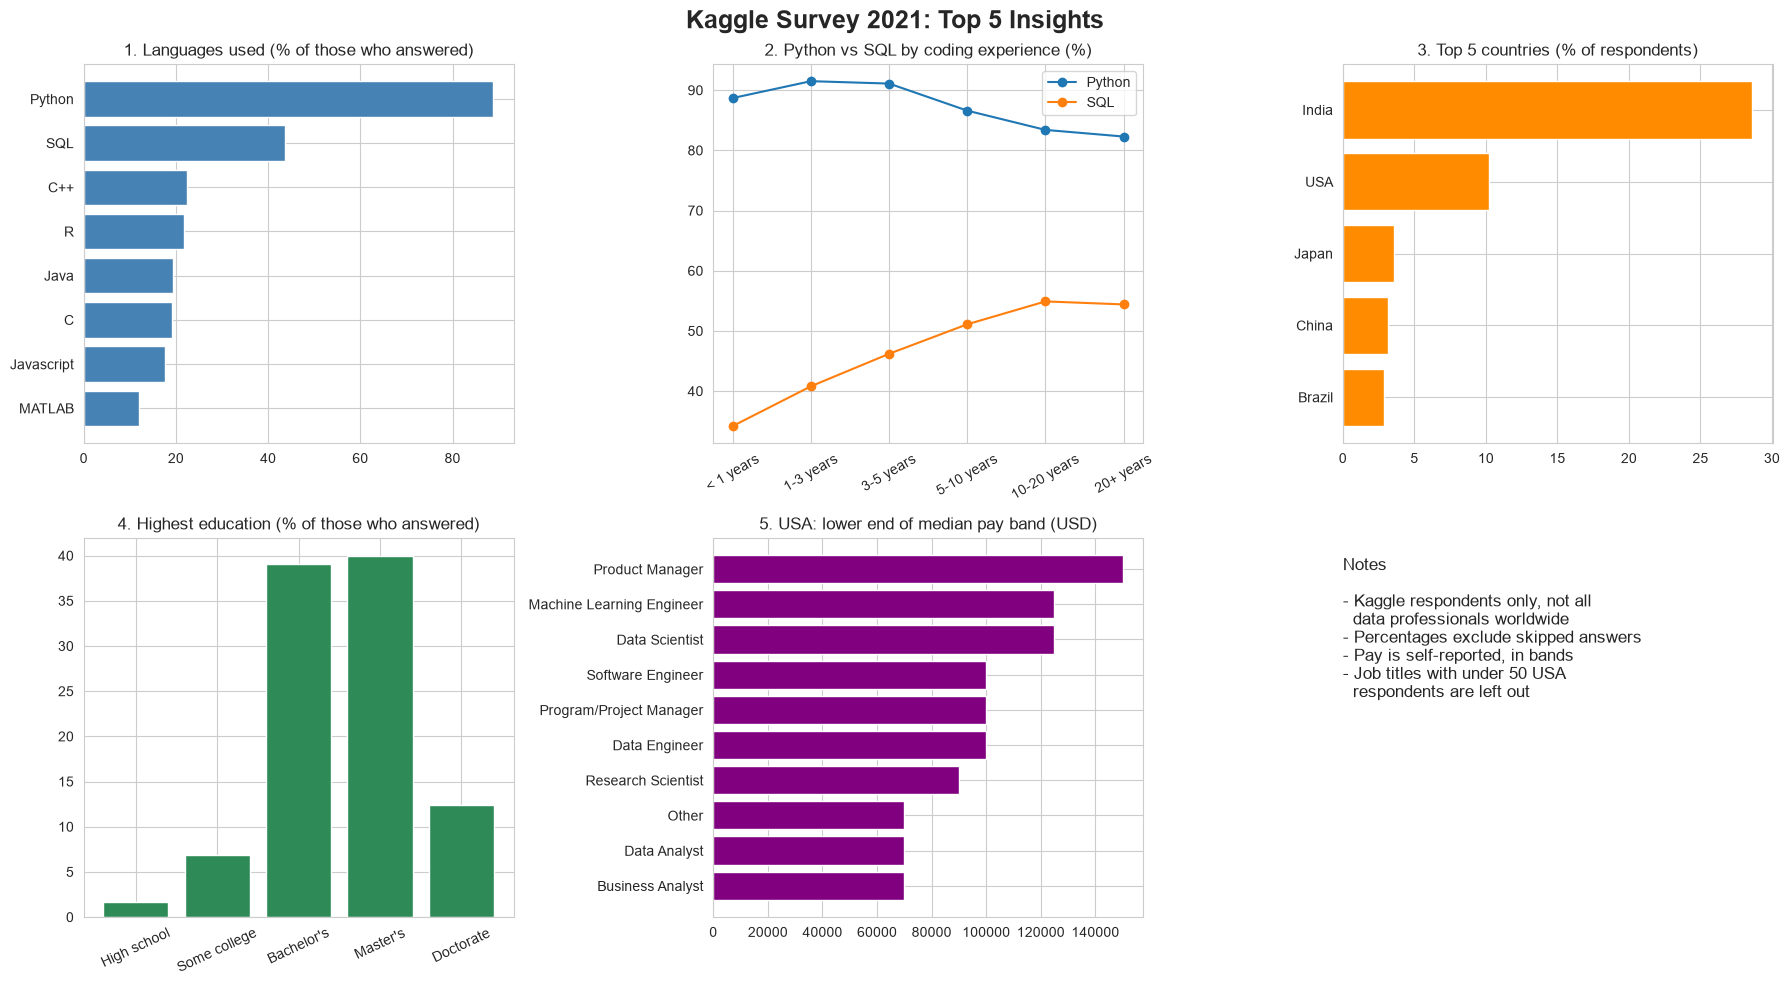

In [27]:
comp_low = [0, 1000, 2000, 3000, 4000, 5000, 7500, 10000, 15000, 20000, 25000, 30000,
            40000, 50000, 60000, 70000, 80000, 90000, 100000, 125000, 150000, 200000,
            250000, 300000, 500000, 1000000]       # lower end of each pay band, in order
low_by_rank = {i + 1: v for i, v in enumerate(comp_low)}

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle("Kaggle Survey 2021: Top 5 Insights", fontsize=18, fontweight="bold")

# 1. Languages
top_lang = lang_share.head(8).sort_values()
axes[0, 0].barh(top_lang.index, top_lang.values, color="steelblue")
axes[0, 0].set_title("1. Languages used (% of those who answered)")

# 2. Python vs SQL by experience
exp_plot = pd.DataFrame({"Python": py_by_exp, "SQL": sql_by_exp}).dropna()
exp_plot.plot(ax=axes[0, 1], marker="o")
axes[0, 1].set_title("2. Python vs SQL by coding experience (%)")
axes[0, 1].set_xlabel("")
axes[0, 1].tick_params(axis="x", rotation=30)

# 3. Top countries (excluding the 'Other' category)
countries = (df_clean["Q3"].value_counts(normalize=True).drop("Other").head(5) * 100).sort_values()
axes[0, 2].barh(countries.index, countries.values, color="darkorange")
axes[0, 2].set_title("3. Top 5 countries (% of respondents)")

# 4. Education
edu_labels = {1: "High school", 2: "Some college", 3: "Bachelor's", 4: "Master's", 5: "Doctorate"}
edu_share = (df_clean["Education_Level"].value_counts(normalize=True).sort_index() * 100)
axes[1, 0].bar([edu_labels[i] for i in edu_share.index], edu_share.values, color="seagreen")
axes[1, 0].set_title("4. Highest education (% of those who answered)")
axes[1, 0].tick_params(axis="x", rotation=25)

# 5. USA pay by job title
pay = med["median"].map(low_by_rank).sort_values()
axes[1, 1].barh(pay.index, pay.values, color="purple")
axes[1, 1].set_title("5. USA: lower end of median pay band (USD)")

# Notes panel
axes[1, 2].axis("off")
axes[1, 2].text(0, 0.95,
    "Notes\n\n"
    "- Kaggle respondents only, not all\n  data professionals worldwide\n"
    "- Percentages exclude skipped answers\n"
    "- Pay is self-reported, in bands\n"
    "- Job titles with under 50 USA\n  respondents are left out",
    va="top", fontsize=12)

plt.tight_layout()
plt.savefig("images/top5_insights_dashboard.png", dpi=150, bbox_inches="tight")
plt.show()

In [28]:
export = pd.concat([
    df_clean[["Q1", "Q2", "Q3", "Q4", "Q5", "Q6", "Q25",
              "Age_Rank", "Education_Level", "Coding_Experience", "Comp_Rank",
              "Q2_code", "Q3_code", "Q5_code"]],
    flags
], axis=1)
export.to_csv("survey_cleaned_selected_columns.csv", index=False)
print(export.shape)

(25973, 26)
